In [4]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import optuna
from xgboost import XGBRegressor


df = pd.read_csv('pipeline/dataset_Gliwice_20230101_20251231.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp') #musi byc chronologicznie


df = df.dropna()



kolumny_do_modelu = [c for c in df.columns if c not in ['timestamp', 'date', 'Produkcja_PV_Godz_MWh', 'city', 'capacity_factor']]
X = df[kolumny_do_modelu]
y = df['Produkcja_PV_Godz_MWh']


In [5]:
from sklearn.model_selection import TimeSeriesSplit
import numpy as np
tscv = TimeSeriesSplit(n_splits=5, gap=24, test_size=24*30) #sprawdzamy na 5 roznych odcinkach model bedzie mogl zagladac w przyszlosc o 30 dni do przodu, z 24 godzinna przerwa miedzy danymi tetowymi a treningowymi

#timeseries split eden z metod walidacji modelu dla danych w ktorych kolejnoc ma znaczenie (pogoda, produkcja)
#główna różnica jest taka że model nie zagląda w przyszlosc

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

pipeline = Pipeline([
    ('model', XGBRegressor(
        n_estimators=2000,
        early_stopping_rounds=50,
        eval_metric='mae',
        tree_method='hist',
        random_state=42

    ))
])

In [7]:
import optuna

def objective(trial):
    params = {
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
        'reg_alpha':        trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda':       trial.suggest_float('reg_lambda', 0.01, 100, log=True),
    }
    # CV wewnątrz objective
    maes = []
    for tr_idx, te_idx in tscv.split(X):
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]

        model = XGBRegressor(**params, n_estimators=2000,
                             early_stopping_rounds=50,
                             eval_metric='mae', random_state=42)
        model.fit(X_tr, y_tr,
                  eval_set=[(X_te, y_te)], verbose=False)
        maes.append(mean_absolute_error(y_te, model.predict(X_te)))
    return np.mean(maes)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

[I 2026-04-18 14:03:01,536] A new study created in memory with name: no-name-3a69fc25-dcd7-489b-afd4-8750f1dd5efd
Best trial: 0. Best value: 2.39685:   1%|          | 1/100 [00:02<04:48,  2.92s/it]

[I 2026-04-18 14:03:04,464] Trial 0 finished with value: 2.3968480785415918 and parameters: {'max_depth': 6, 'learning_rate': 0.07293157567056836, 'subsample': 0.8214952043423549, 'colsample_bytree': 0.8853218504745868, 'min_child_weight': 15, 'reg_alpha': 8.28511510696089, 'reg_lambda': 10.784226817219015}. Best is trial 0 with value: 2.3968480785415918.


Best trial: 1. Best value: 2.30357:   2%|▏         | 2/100 [00:05<04:25,  2.70s/it]

[I 2026-04-18 14:03:07,020] Trial 1 finished with value: 2.3035660678786765 and parameters: {'max_depth': 8, 'learning_rate': 0.08170311534078521, 'subsample': 0.5232274842438336, 'colsample_bytree': 0.7032858102974466, 'min_child_weight': 11, 'reg_alpha': 3.2553966995370334, 'reg_lambda': 0.41725417301362544}. Best is trial 1 with value: 2.3035660678786765.


Best trial: 1. Best value: 2.30357:   3%|▎         | 3/100 [00:08<04:47,  2.96s/it]

[I 2026-04-18 14:03:10,285] Trial 2 finished with value: 2.9240566635298775 and parameters: {'max_depth': 3, 'learning_rate': 0.043006293991384933, 'subsample': 0.8632048687905097, 'colsample_bytree': 0.9328393137206339, 'min_child_weight': 8, 'reg_alpha': 0.003358829878208496, 'reg_lambda': 0.20299033874682662}. Best is trial 1 with value: 2.3035660678786765.


Best trial: 1. Best value: 2.30357:   4%|▍         | 4/100 [00:12<04:58,  3.11s/it]

[I 2026-04-18 14:03:13,613] Trial 3 finished with value: 2.9284162608671545 and parameters: {'max_depth': 3, 'learning_rate': 0.03678521273136329, 'subsample': 0.9019407165115148, 'colsample_bytree': 0.6339474492969746, 'min_child_weight': 1, 'reg_alpha': 1.732744061029547, 'reg_lambda': 8.016830397938051}. Best is trial 1 with value: 2.3035660678786765.


Best trial: 4. Best value: 2.29513:   5%|▌         | 5/100 [00:15<05:19,  3.36s/it]

[I 2026-04-18 14:03:17,430] Trial 4 finished with value: 2.2951334487201995 and parameters: {'max_depth': 10, 'learning_rate': 0.10088129821152227, 'subsample': 0.8770931567730837, 'colsample_bytree': 0.7840307151208428, 'min_child_weight': 13, 'reg_alpha': 1.5322210760393025, 'reg_lambda': 0.02580350450578037}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:   6%|▌         | 6/100 [00:19<05:21,  3.42s/it]

[I 2026-04-18 14:03:20,952] Trial 5 finished with value: 2.874775866923877 and parameters: {'max_depth': 3, 'learning_rate': 0.03415386018941997, 'subsample': 0.935191019534519, 'colsample_bytree': 0.6453063774859457, 'min_child_weight': 5, 'reg_alpha': 3.574624865312275, 'reg_lambda': 0.3421801580079282}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:   7%|▋         | 7/100 [00:21<04:45,  3.07s/it]

[I 2026-04-18 14:03:23,313] Trial 6 finished with value: 2.381786916880512 and parameters: {'max_depth': 6, 'learning_rate': 0.06759027503846794, 'subsample': 0.8952615758225942, 'colsample_bytree': 0.7939163785560401, 'min_child_weight': 13, 'reg_alpha': 1.5619466275313985, 'reg_lambda': 0.08856624848637391}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:   8%|▊         | 8/100 [00:25<04:53,  3.19s/it]

[I 2026-04-18 14:03:26,755] Trial 7 finished with value: 2.3598613974913882 and parameters: {'max_depth': 6, 'learning_rate': 0.1673654538741879, 'subsample': 0.9589185898226997, 'colsample_bytree': 0.6710807942293121, 'min_child_weight': 11, 'reg_alpha': 0.8019057495039852, 'reg_lambda': 3.7515300584377935}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:   9%|▉         | 9/100 [00:28<04:41,  3.09s/it]

[I 2026-04-18 14:03:29,632] Trial 8 finished with value: 2.4158540786641773 and parameters: {'max_depth': 6, 'learning_rate': 0.03851983231767291, 'subsample': 0.6684192998993329, 'colsample_bytree': 0.5460039840721485, 'min_child_weight': 9, 'reg_alpha': 0.09624652831196372, 'reg_lambda': 4.151573759787414}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:  10%|█         | 10/100 [00:34<06:03,  4.04s/it]

[I 2026-04-18 14:03:35,779] Trial 9 finished with value: 2.299549987521794 and parameters: {'max_depth': 9, 'learning_rate': 0.06280174228596928, 'subsample': 0.8155306343232916, 'colsample_bytree': 0.6855021320332746, 'min_child_weight': 2, 'reg_alpha': 0.04994354213690079, 'reg_lambda': 0.01774900629207401}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:  11%|█         | 11/100 [00:56<14:02,  9.46s/it]

[I 2026-04-18 14:03:57,548] Trial 10 finished with value: 2.3991970283665935 and parameters: {'max_depth': 10, 'learning_rate': 0.011767007371241998, 'subsample': 0.7114894472336847, 'colsample_bytree': 0.7988321584504122, 'min_child_weight': 19, 'reg_alpha': 0.27845233725400004, 'reg_lambda': 55.78874945138665}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:  12%|█▏        | 12/100 [00:58<10:40,  7.28s/it]

[I 2026-04-18 14:03:59,828] Trial 11 finished with value: 2.3578739882780266 and parameters: {'max_depth': 10, 'learning_rate': 0.17136453202993615, 'subsample': 0.7847168787581915, 'colsample_bytree': 0.8445035858871346, 'min_child_weight': 1, 'reg_alpha': 0.026675798207272464, 'reg_lambda': 0.011021535280281963}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:  13%|█▎        | 13/100 [00:59<07:56,  5.48s/it]

[I 2026-04-18 14:04:01,165] Trial 12 finished with value: 2.3436848563555097 and parameters: {'max_depth': 8, 'learning_rate': 0.27156290961800006, 'subsample': 0.6579851919176476, 'colsample_bytree': 0.7430090590591982, 'min_child_weight': 17, 'reg_alpha': 0.01911592834952616, 'reg_lambda': 0.017118861034106446}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 4. Best value: 2.29513:  14%|█▍        | 14/100 [01:02<06:50,  4.77s/it]

[I 2026-04-18 14:04:04,311] Trial 13 finished with value: 2.3375007000258616 and parameters: {'max_depth': 9, 'learning_rate': 0.11550430437235684, 'subsample': 0.993772672010978, 'colsample_bytree': 0.9830218287607873, 'min_child_weight': 6, 'reg_alpha': 0.12445218014095995, 'reg_lambda': 0.04812399956748511}. Best is trial 4 with value: 2.2951334487201995.


Best trial: 14. Best value: 2.26022:  15%|█▌        | 15/100 [01:11<08:18,  5.87s/it]

[I 2026-04-18 14:04:12,707] Trial 14 finished with value: 2.260222312428943 and parameters: {'max_depth': 8, 'learning_rate': 0.018105474399515094, 'subsample': 0.7761695676005653, 'colsample_bytree': 0.5580320440921097, 'min_child_weight': 5, 'reg_alpha': 0.0011690930176112909, 'reg_lambda': 0.04151709582542363}. Best is trial 14 with value: 2.260222312428943.


Best trial: 14. Best value: 2.26022:  16%|█▌        | 16/100 [01:19<09:14,  6.60s/it]

[I 2026-04-18 14:04:21,010] Trial 15 finished with value: 2.2830014752726693 and parameters: {'max_depth': 8, 'learning_rate': 0.018221477109448735, 'subsample': 0.734229691900694, 'colsample_bytree': 0.5054184930403438, 'min_child_weight': 5, 'reg_alpha': 0.0010007090252944384, 'reg_lambda': 0.05487727508723681}. Best is trial 14 with value: 2.260222312428943.


Best trial: 14. Best value: 2.26022:  17%|█▋        | 17/100 [01:32<11:42,  8.47s/it]

[I 2026-04-18 14:04:33,818] Trial 16 finished with value: 2.269000996921913 and parameters: {'max_depth': 8, 'learning_rate': 0.01732030934668183, 'subsample': 0.5939383494325459, 'colsample_bytree': 0.5107399737546087, 'min_child_weight': 4, 'reg_alpha': 0.0011430619290595547, 'reg_lambda': 0.09000417246951355}. Best is trial 14 with value: 2.260222312428943.


Best trial: 14. Best value: 2.26022:  18%|█▊        | 18/100 [01:39<11:03,  8.09s/it]

[I 2026-04-18 14:04:41,026] Trial 17 finished with value: 2.295701696273879 and parameters: {'max_depth': 7, 'learning_rate': 0.01927508538350182, 'subsample': 0.5533263031167641, 'colsample_bytree': 0.5906837204311662, 'min_child_weight': 4, 'reg_alpha': 0.005743979372866808, 'reg_lambda': 1.3963087495884492}. Best is trial 14 with value: 2.260222312428943.


Best trial: 14. Best value: 2.26022:  19%|█▉        | 19/100 [01:46<10:21,  7.68s/it]

[I 2026-04-18 14:04:47,752] Trial 18 finished with value: 2.5287160297844222 and parameters: {'max_depth': 5, 'learning_rate': 0.010746276203740262, 'subsample': 0.5923037873445648, 'colsample_bytree': 0.5004129071818274, 'min_child_weight': 7, 'reg_alpha': 0.0012193546776343997, 'reg_lambda': 1.2060850370221967}. Best is trial 14 with value: 2.260222312428943.


Best trial: 14. Best value: 2.26022:  20%|██        | 20/100 [01:52<09:40,  7.25s/it]

[I 2026-04-18 14:04:54,005] Trial 19 finished with value: 2.3109923447257077 and parameters: {'max_depth': 7, 'learning_rate': 0.022335799592691802, 'subsample': 0.626589962281464, 'colsample_bytree': 0.586374992637793, 'min_child_weight': 3, 'reg_alpha': 0.005632919209654503, 'reg_lambda': 0.13299589108215382}. Best is trial 14 with value: 2.260222312428943.


Best trial: 20. Best value: 2.24341:  21%|██        | 21/100 [02:00<09:46,  7.42s/it]

[I 2026-04-18 14:05:01,818] Trial 20 finished with value: 2.243413575873981 and parameters: {'max_depth': 9, 'learning_rate': 0.02562940276615708, 'subsample': 0.7128823137309441, 'colsample_bytree': 0.5952210122550128, 'min_child_weight': 9, 'reg_alpha': 0.0026152791537186583, 'reg_lambda': 0.05182161265813736}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  22%|██▏       | 22/100 [02:07<09:24,  7.24s/it]

[I 2026-04-18 14:05:08,635] Trial 21 finished with value: 2.2857535539309106 and parameters: {'max_depth': 9, 'learning_rate': 0.025209492389242274, 'subsample': 0.7203048183579994, 'colsample_bytree': 0.5666009763993145, 'min_child_weight': 9, 'reg_alpha': 0.0026849415889431895, 'reg_lambda': 0.04462402931192131}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  23%|██▎       | 23/100 [02:19<11:11,  8.72s/it]

[I 2026-04-18 14:05:20,826] Trial 22 finished with value: 2.261919234233638 and parameters: {'max_depth': 8, 'learning_rate': 0.014676338862272096, 'subsample': 0.7758086843496637, 'colsample_bytree': 0.5393230194163358, 'min_child_weight': 7, 'reg_alpha': 0.012960547537664782, 'reg_lambda': 0.3679417168671181}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  24%|██▍       | 24/100 [02:31<12:25,  9.81s/it]

[I 2026-04-18 14:05:33,171] Trial 23 finished with value: 2.269201710203668 and parameters: {'max_depth': 9, 'learning_rate': 0.014194998764446087, 'subsample': 0.7778135344855884, 'colsample_bytree': 0.6168836211001159, 'min_child_weight': 7, 'reg_alpha': 0.011075064562198053, 'reg_lambda': 0.42229683050792344}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  25%|██▌       | 25/100 [02:36<10:20,  8.28s/it]

[I 2026-04-18 14:05:37,878] Trial 24 finished with value: 2.3410997606968875 and parameters: {'max_depth': 7, 'learning_rate': 0.024522936717931737, 'subsample': 0.6878785408672918, 'colsample_bytree': 0.5490981692111001, 'min_child_weight': 10, 'reg_alpha': 0.002593756922105855, 'reg_lambda': 0.20013091368042618}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  26%|██▌       | 26/100 [02:48<11:36,  9.42s/it]

[I 2026-04-18 14:05:49,952] Trial 25 finished with value: 2.2562156935327935 and parameters: {'max_depth': 8, 'learning_rate': 0.013955784385147373, 'subsample': 0.7724116444843534, 'colsample_bytree': 0.5935622881575563, 'min_child_weight': 7, 'reg_alpha': 0.011013762799255146, 'reg_lambda': 0.7159722499620105}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  27%|██▋       | 27/100 [03:04<13:54, 11.43s/it]

[I 2026-04-18 14:06:06,066] Trial 26 finished with value: 2.2973098181821636 and parameters: {'max_depth': 9, 'learning_rate': 0.02897810060815495, 'subsample': 0.8156365414318831, 'colsample_bytree': 0.6054444216393733, 'min_child_weight': 12, 'reg_alpha': 0.006101686695387399, 'reg_lambda': 60.127984846463235}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  28%|██▊       | 28/100 [03:07<10:36,  8.84s/it]

[I 2026-04-18 14:06:08,880] Trial 27 finished with value: 2.5046141621605202 and parameters: {'max_depth': 5, 'learning_rate': 0.04626080911125793, 'subsample': 0.7552043089635004, 'colsample_bytree': 0.7324188389357826, 'min_child_weight': 9, 'reg_alpha': 0.0019213086546649907, 'reg_lambda': 0.762181359790492}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  29%|██▉       | 29/100 [03:15<10:16,  8.68s/it]

[I 2026-04-18 14:06:17,179] Trial 28 finished with value: 2.3273143061344426 and parameters: {'max_depth': 7, 'learning_rate': 0.012423595212401954, 'subsample': 0.8393164327602721, 'colsample_bytree': 0.6577410362470486, 'min_child_weight': 6, 'reg_alpha': 0.03668189114132102, 'reg_lambda': 0.031199928343283393}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  30%|███       | 30/100 [03:19<08:22,  7.18s/it]

[I 2026-04-18 14:06:20,849] Trial 29 finished with value: 2.5350070778766436 and parameters: {'max_depth': 5, 'learning_rate': 0.029723387085202516, 'subsample': 0.6850491857925166, 'colsample_bytree': 0.7053275695878958, 'min_child_weight': 15, 'reg_alpha': 0.009347114969401998, 'reg_lambda': 26.26031818691188}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  31%|███       | 31/100 [03:40<13:13, 11.50s/it]

[I 2026-04-18 14:06:42,438] Trial 30 finished with value: 2.28587645148463 and parameters: {'max_depth': 10, 'learning_rate': 0.015982089305645496, 'subsample': 0.83296337057554, 'colsample_bytree': 0.5763385289480955, 'min_child_weight': 3, 'reg_alpha': 0.004337876578243224, 'reg_lambda': 3.24624055412531}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  32%|███▏      | 32/100 [03:53<13:18, 11.74s/it]

[I 2026-04-18 14:06:54,723] Trial 31 finished with value: 2.2597639652675925 and parameters: {'max_depth': 8, 'learning_rate': 0.013927275351501522, 'subsample': 0.7779586227711274, 'colsample_bytree': 0.5319375145095508, 'min_child_weight': 7, 'reg_alpha': 0.01406971701368552, 'reg_lambda': 0.5547064404373167}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  33%|███▎      | 33/100 [04:06<13:28, 12.07s/it]

[I 2026-04-18 14:07:07,569] Trial 32 finished with value: 2.301299150960112 and parameters: {'max_depth': 8, 'learning_rate': 0.010081016296764915, 'subsample': 0.7488171456925006, 'colsample_bytree': 0.5379632281341752, 'min_child_weight': 8, 'reg_alpha': 0.001796595437751596, 'reg_lambda': 0.7271348453720299}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  34%|███▍      | 34/100 [04:14<11:56, 10.85s/it]

[I 2026-04-18 14:07:15,584] Trial 33 finished with value: 2.281722318587822 and parameters: {'max_depth': 8, 'learning_rate': 0.02079951272683946, 'subsample': 0.7919772251353355, 'colsample_bytree': 0.6175470139009384, 'min_child_weight': 10, 'reg_alpha': 0.00805082513154863, 'reg_lambda': 1.7721885294931334}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  35%|███▌      | 35/100 [04:25<11:48, 10.90s/it]

[I 2026-04-18 14:07:26,602] Trial 34 finished with value: 2.273455085013359 and parameters: {'max_depth': 9, 'learning_rate': 0.014460635958395985, 'subsample': 0.7200195854706494, 'colsample_bytree': 0.5647970665995788, 'min_child_weight': 6, 'reg_alpha': 0.019978367858697534, 'reg_lambda': 0.19340015240304576}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  36%|███▌      | 36/100 [04:33<10:43, 10.05s/it]

[I 2026-04-18 14:07:34,675] Trial 35 finished with value: 2.3320902733311204 and parameters: {'max_depth': 7, 'learning_rate': 0.013078351614011375, 'subsample': 0.858451171758592, 'colsample_bytree': 0.6317940290332118, 'min_child_weight': 8, 'reg_alpha': 0.003377717636098858, 'reg_lambda': 0.582803713953235}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  37%|███▋      | 37/100 [04:40<09:49,  9.36s/it]

[I 2026-04-18 14:07:42,414] Trial 36 finished with value: 2.3022118710390163 and parameters: {'max_depth': 9, 'learning_rate': 0.029965601447490022, 'subsample': 0.8001758730616189, 'colsample_bytree': 0.530272868499144, 'min_child_weight': 5, 'reg_alpha': 0.06146478596694886, 'reg_lambda': 0.0886780369108131}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  38%|███▊      | 38/100 [04:44<07:46,  7.52s/it]

[I 2026-04-18 14:07:45,645] Trial 37 finished with value: 2.346058025894772 and parameters: {'max_depth': 8, 'learning_rate': 0.053005069145303355, 'subsample': 0.7619370339749619, 'colsample_bytree': 0.6022972581109398, 'min_child_weight': 12, 'reg_alpha': 0.001668816917692042, 'reg_lambda': 9.53766715970417}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  39%|███▉      | 39/100 [05:03<11:10, 11.00s/it]

[I 2026-04-18 14:08:04,759] Trial 38 finished with value: 2.303922113328497 and parameters: {'max_depth': 10, 'learning_rate': 0.017434722501032493, 'subsample': 0.6372879012879091, 'colsample_bytree': 0.8918149443932217, 'min_child_weight': 8, 'reg_alpha': 9.23249233235825, 'reg_lambda': 0.26156579118004275}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  40%|████      | 40/100 [05:08<09:20,  9.34s/it]

[I 2026-04-18 14:08:10,235] Trial 39 finished with value: 2.3165592843704417 and parameters: {'max_depth': 7, 'learning_rate': 0.02271762815370324, 'subsample': 0.6989695331693674, 'colsample_bytree': 0.6411525754314016, 'min_child_weight': 4, 'reg_alpha': 0.2623201119211454, 'reg_lambda': 0.12289564815950907}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  41%|████      | 41/100 [05:15<08:27,  8.60s/it]

[I 2026-04-18 14:08:17,094] Trial 40 finished with value: 2.2595128658903954 and parameters: {'max_depth': 9, 'learning_rate': 0.03696576783846833, 'subsample': 0.8753709269037693, 'colsample_bytree': 0.7000201986111771, 'min_child_weight': 14, 'reg_alpha': 0.013508265651908458, 'reg_lambda': 2.3527846986305003}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  42%|████▏     | 42/100 [05:21<07:30,  7.76s/it]

[I 2026-04-18 14:08:22,913] Trial 41 finished with value: 2.2933568538542537 and parameters: {'max_depth': 9, 'learning_rate': 0.04048609829633974, 'subsample': 0.8950387575015679, 'colsample_bytree': 0.6925183043063701, 'min_child_weight': 15, 'reg_alpha': 0.01556896625725247, 'reg_lambda': 6.241397997374816}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  43%|████▎     | 43/100 [05:28<07:04,  7.44s/it]

[I 2026-04-18 14:08:29,614] Trial 42 finished with value: 2.293049170013473 and parameters: {'max_depth': 8, 'learning_rate': 0.03294694255178856, 'subsample': 0.9271464940336873, 'colsample_bytree': 0.7764650988619428, 'min_child_weight': 13, 'reg_alpha': 0.003873637045618618, 'reg_lambda': 2.1187072114296392}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  44%|████▍     | 44/100 [05:32<06:01,  6.45s/it]

[I 2026-04-18 14:08:33,735] Trial 43 finished with value: 2.2732318327561303 and parameters: {'max_depth': 9, 'learning_rate': 0.04567261634003317, 'subsample': 0.8528798631832919, 'colsample_bytree': 0.7187830757792124, 'min_child_weight': 16, 'reg_alpha': 0.0276858573115072, 'reg_lambda': 2.784436724301056}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  45%|████▌     | 45/100 [05:40<06:24,  6.99s/it]

[I 2026-04-18 14:08:41,998] Trial 44 finished with value: 2.2941201536930764 and parameters: {'max_depth': 10, 'learning_rate': 0.02598209583069423, 'subsample': 0.8743068062031983, 'colsample_bytree': 0.5664014138895089, 'min_child_weight': 11, 'reg_alpha': 0.009236621557295993, 'reg_lambda': 16.829680135812723}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  46%|████▌     | 46/100 [05:46<06:02,  6.72s/it]

[I 2026-04-18 14:08:48,077] Trial 45 finished with value: 2.3663688795708424 and parameters: {'max_depth': 8, 'learning_rate': 0.020446360044162004, 'subsample': 0.8113004638715442, 'colsample_bytree': 0.6693463148694516, 'min_child_weight': 20, 'reg_alpha': 0.09399454066799082, 'reg_lambda': 5.036950256418397}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  47%|████▋     | 47/100 [06:02<08:28,  9.60s/it]

[I 2026-04-18 14:09:04,398] Trial 46 finished with value: 2.2566869944801837 and parameters: {'max_depth': 9, 'learning_rate': 0.011879825285790645, 'subsample': 0.7366721418731128, 'colsample_bytree': 0.5245873531418696, 'min_child_weight': 7, 'reg_alpha': 0.002516311418618188, 'reg_lambda': 0.025275761840304087}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  48%|████▊     | 48/100 [06:06<06:42,  7.74s/it]

[I 2026-04-18 14:09:07,801] Trial 47 finished with value: 2.3859683061839974 and parameters: {'max_depth': 10, 'learning_rate': 0.081048801929345, 'subsample': 0.7418681859930494, 'colsample_bytree': 0.519643702157474, 'min_child_weight': 14, 'reg_alpha': 0.04093893771838278, 'reg_lambda': 0.013214862664117324}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  49%|████▉     | 49/100 [06:20<08:19,  9.80s/it]

[I 2026-04-18 14:09:22,418] Trial 48 finished with value: 2.300660321523145 and parameters: {'max_depth': 9, 'learning_rate': 0.011269448863505583, 'subsample': 0.668758192701088, 'colsample_bytree': 0.5267581572991255, 'min_child_weight': 10, 'reg_alpha': 0.0068880629698093495, 'reg_lambda': 0.023356679410375503}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  50%|█████     | 50/100 [06:24<06:43,  8.06s/it]

[I 2026-04-18 14:09:26,419] Trial 49 finished with value: 2.29979514111643 and parameters: {'max_depth': 10, 'learning_rate': 0.056248845898232674, 'subsample': 0.9239837306639169, 'colsample_bytree': 0.6265706805108976, 'min_child_weight': 18, 'reg_alpha': 0.022833321230519368, 'reg_lambda': 0.9785854108199147}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  51%|█████     | 51/100 [06:29<05:50,  7.14s/it]

[I 2026-04-18 14:09:31,419] Trial 50 finished with value: 2.8087317608472064 and parameters: {'max_depth': 4, 'learning_rate': 0.012510497416603749, 'subsample': 0.9699039340876079, 'colsample_bytree': 0.8332752599481551, 'min_child_weight': 12, 'reg_alpha': 0.0024039799203133035, 'reg_lambda': 2.268836563604322}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  52%|█████▏    | 52/100 [06:40<06:39,  8.33s/it]

[I 2026-04-18 14:09:42,516] Trial 51 finished with value: 2.253860453930506 and parameters: {'max_depth': 8, 'learning_rate': 0.01563518108861102, 'subsample': 0.7668909285791353, 'colsample_bytree': 0.5606728088248079, 'min_child_weight': 6, 'reg_alpha': 0.0015291100018820854, 'reg_lambda': 0.061275481505856155}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  53%|█████▎    | 53/100 [06:52<07:22,  9.42s/it]

[I 2026-04-18 14:09:54,466] Trial 52 finished with value: 2.273166177312884 and parameters: {'max_depth': 9, 'learning_rate': 0.0159348231816594, 'subsample': 0.7214385316099563, 'colsample_bytree': 0.5863117390747843, 'min_child_weight': 6, 'reg_alpha': 0.004255000876292074, 'reg_lambda': 0.061317037760456834}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  54%|█████▍    | 54/100 [07:04<07:49, 10.20s/it]

[I 2026-04-18 14:10:06,487] Trial 53 finished with value: 2.272164990053853 and parameters: {'max_depth': 8, 'learning_rate': 0.012954691922445881, 'subsample': 0.7639988882764248, 'colsample_bytree': 0.549228411924608, 'min_child_weight': 7, 'reg_alpha': 0.0016762034915870953, 'reg_lambda': 0.02931840799833207}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  55%|█████▌    | 55/100 [07:23<09:38, 12.85s/it]

[I 2026-04-18 14:10:25,538] Trial 54 finished with value: 2.287306887328045 and parameters: {'max_depth': 9, 'learning_rate': 0.010294097001771562, 'subsample': 0.7315072697877429, 'colsample_bytree': 0.6513852894534655, 'min_child_weight': 9, 'reg_alpha': 4.436194170703247, 'reg_lambda': 0.06336717203518674}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  56%|█████▌    | 56/100 [07:33<08:38, 11.79s/it]

[I 2026-04-18 14:10:34,853] Trial 55 finished with value: 2.2773070753538014 and parameters: {'max_depth': 8, 'learning_rate': 0.01579506567971216, 'subsample': 0.8006101998012852, 'colsample_bytree': 0.7636541978553613, 'min_child_weight': 7, 'reg_alpha': 0.014148488713193233, 'reg_lambda': 0.010454996077069938}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  57%|█████▋    | 57/100 [07:37<06:55,  9.66s/it]

[I 2026-04-18 14:10:39,528] Trial 56 finished with value: 2.3592947011694965 and parameters: {'max_depth': 6, 'learning_rate': 0.03737834377428159, 'subsample': 0.6959253523166857, 'colsample_bytree': 0.5012664404128347, 'min_child_weight': 8, 'reg_alpha': 0.004653567023401005, 'reg_lambda': 0.019687605631163205}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  58%|█████▊    | 58/100 [07:49<07:15, 10.36s/it]

[I 2026-04-18 14:10:51,538] Trial 57 finished with value: 2.249985530224617 and parameters: {'max_depth': 9, 'learning_rate': 0.019314414398921526, 'subsample': 0.8350080074952049, 'colsample_bytree': 0.6052455567930379, 'min_child_weight': 9, 'reg_alpha': 0.0027955062157003384, 'reg_lambda': 0.521069726749112}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  59%|█████▉    | 59/100 [07:56<06:16,  9.19s/it]

[I 2026-04-18 14:10:57,977] Trial 58 finished with value: 2.295865092668958 and parameters: {'max_depth': 9, 'learning_rate': 0.03395954453572266, 'subsample': 0.8316362048650099, 'colsample_bytree': 0.6036825745983512, 'min_child_weight': 9, 'reg_alpha': 0.0029132553581970072, 'reg_lambda': 0.13341017974623817}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  60%|██████    | 60/100 [08:08<06:47, 10.18s/it]

[I 2026-04-18 14:11:10,479] Trial 59 finished with value: 2.2779711250696675 and parameters: {'max_depth': 10, 'learning_rate': 0.0190960609109747, 'subsample': 0.88578743891876, 'colsample_bytree': 0.6763994313731917, 'min_child_weight': 10, 'reg_alpha': 0.002289821745674972, 'reg_lambda': 0.032498966053662724}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  61%|██████    | 61/100 [08:15<05:52,  9.04s/it]

[I 2026-04-18 14:11:16,869] Trial 60 finished with value: 2.297888546022867 and parameters: {'max_depth': 9, 'learning_rate': 0.02587596232097365, 'subsample': 0.7065553982348389, 'colsample_bytree': 0.5843952830962285, 'min_child_weight': 11, 'reg_alpha': 0.0012833198704532759, 'reg_lambda': 0.2958963018704757}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  62%|██████▏   | 62/100 [08:27<06:18,  9.97s/it]

[I 2026-04-18 14:11:28,997] Trial 61 finished with value: 2.2893023219894704 and parameters: {'max_depth': 8, 'learning_rate': 0.011521798549580986, 'subsample': 0.781320772452122, 'colsample_bytree': 0.56094849141507, 'min_child_weight': 8, 'reg_alpha': 0.005552843475776707, 'reg_lambda': 0.48430352742333804}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  63%|██████▎   | 63/100 [08:44<07:31, 12.21s/it]

[I 2026-04-18 14:11:46,440] Trial 62 finished with value: 2.2664744570783437 and parameters: {'max_depth': 9, 'learning_rate': 0.013796490816032736, 'subsample': 0.8494511560194087, 'colsample_bytree': 0.5249078311009034, 'min_child_weight': 6, 'reg_alpha': 0.003257523764960775, 'reg_lambda': 1.0103869575257614}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  64%|██████▍   | 64/100 [08:55<06:58, 11.63s/it]

[I 2026-04-18 14:11:56,720] Trial 63 finished with value: 2.295881336063624 and parameters: {'max_depth': 8, 'learning_rate': 0.016350192675206494, 'subsample': 0.5056324028479763, 'colsample_bytree': 0.5465619019528694, 'min_child_weight': 5, 'reg_alpha': 0.011021015064574794, 'reg_lambda': 0.589458269877818}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  65%|██████▌   | 65/100 [09:00<05:44,  9.84s/it]

[I 2026-04-18 14:12:02,378] Trial 64 finished with value: 2.3348334097356584 and parameters: {'max_depth': 7, 'learning_rate': 0.023194069612066517, 'subsample': 0.7665400651683296, 'colsample_bytree': 0.5767734075330482, 'min_child_weight': 7, 'reg_alpha': 0.0013460857640798206, 'reg_lambda': 1.6782643806159836}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  66%|██████▌   | 66/100 [09:11<05:45, 10.15s/it]

[I 2026-04-18 14:12:13,257] Trial 65 finished with value: 2.28203268521049 and parameters: {'max_depth': 9, 'learning_rate': 0.0207811072853731, 'subsample': 0.8228293211497164, 'colsample_bytree': 0.5986445829086626, 'min_child_weight': 9, 'reg_alpha': 0.0010092945522663995, 'reg_lambda': 1.293695302370035}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  67%|██████▋   | 67/100 [09:21<05:33, 10.12s/it]

[I 2026-04-18 14:12:23,289] Trial 66 finished with value: 2.257642432753242 and parameters: {'max_depth': 8, 'learning_rate': 0.018314419556133808, 'subsample': 0.9125418755955972, 'colsample_bytree': 0.6142503129868485, 'min_child_weight': 7, 'reg_alpha': 0.006768948926962671, 'reg_lambda': 0.23823540902084614}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  68%|██████▊   | 68/100 [09:24<04:15,  7.97s/it]

[I 2026-04-18 14:12:26,262] Trial 67 finished with value: 2.471231134962607 and parameters: {'max_depth': 10, 'learning_rate': 0.28858354107043876, 'subsample': 0.9491316690293893, 'colsample_bytree': 0.6100193404856616, 'min_child_weight': 4, 'reg_alpha': 0.797345470774019, 'reg_lambda': 0.17451100828958802}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  69%|██████▉   | 69/100 [09:31<03:53,  7.54s/it]

[I 2026-04-18 14:12:32,794] Trial 68 finished with value: 2.291993391529615 and parameters: {'max_depth': 7, 'learning_rate': 0.028165855259373037, 'subsample': 0.9043619543038404, 'colsample_bytree': 0.6306454174998503, 'min_child_weight': 3, 'reg_alpha': 0.007762845046938216, 'reg_lambda': 0.04304803764330865}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  70%|███████   | 70/100 [09:39<03:57,  7.90s/it]

[I 2026-04-18 14:12:41,540] Trial 69 finished with value: 2.299755213617855 and parameters: {'max_depth': 8, 'learning_rate': 0.017531430943679663, 'subsample': 0.8698057253516959, 'colsample_bytree': 0.9870772172330318, 'min_child_weight': 6, 'reg_alpha': 0.0019690734078479945, 'reg_lambda': 0.26560546898380133}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  71%|███████   | 71/100 [09:51<04:20,  8.98s/it]

[I 2026-04-18 14:12:53,043] Trial 70 finished with value: 2.2749990693358053 and parameters: {'max_depth': 9, 'learning_rate': 0.019374801562219688, 'subsample': 0.9032426609825838, 'colsample_bytree': 0.6604533377993681, 'min_child_weight': 9, 'reg_alpha': 0.004993091753860308, 'reg_lambda': 0.06683709442211827}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  72%|███████▏  | 72/100 [10:02<04:32,  9.72s/it]

[I 2026-04-18 14:13:04,489] Trial 71 finished with value: 2.279317950388175 and parameters: {'max_depth': 8, 'learning_rate': 0.015031173747356748, 'subsample': 0.751719552688717, 'colsample_bytree': 0.515377372233902, 'min_child_weight': 7, 'reg_alpha': 0.017360960060103008, 'reg_lambda': 0.7830736967297124}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  73%|███████▎  | 73/100 [10:12<04:22,  9.72s/it]

[I 2026-04-18 14:13:14,209] Trial 72 finished with value: 2.283155749916264 and parameters: {'max_depth': 8, 'learning_rate': 0.013732815470432336, 'subsample': 0.7932385166136579, 'colsample_bytree': 0.5539082181858381, 'min_child_weight': 8, 'reg_alpha': 0.011671247971933129, 'reg_lambda': 0.4073136224647869}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  74%|███████▍  | 74/100 [10:31<05:23, 12.43s/it]

[I 2026-04-18 14:13:32,974] Trial 73 finished with value: 2.2641038667220243 and parameters: {'max_depth': 9, 'learning_rate': 0.011408787400281863, 'subsample': 0.7278587542059132, 'colsample_bytree': 0.5741368514298395, 'min_child_weight': 5, 'reg_alpha': 0.028928373117821263, 'reg_lambda': 0.10743334388066031}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  75%|███████▌  | 75/100 [10:37<04:20, 10.43s/it]

[I 2026-04-18 14:13:38,711] Trial 74 finished with value: 2.324143538508491 and parameters: {'max_depth': 7, 'learning_rate': 0.02179104145990999, 'subsample': 0.914099431149711, 'colsample_bytree': 0.622037997146689, 'min_child_weight': 6, 'reg_alpha': 0.0035895732428787596, 'reg_lambda': 0.5488736586225265}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  76%|███████▌  | 76/100 [10:47<04:10, 10.43s/it]

[I 2026-04-18 14:13:49,158] Trial 75 finished with value: 2.275088613590163 and parameters: {'max_depth': 8, 'learning_rate': 0.017082205655593076, 'subsample': 0.8436650008610456, 'colsample_bytree': 0.5381145628380862, 'min_child_weight': 7, 'reg_alpha': 0.006306289210293631, 'reg_lambda': 0.015006730200251709}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  77%|███████▋  | 77/100 [10:52<03:22,  8.80s/it]

[I 2026-04-18 14:13:54,155] Trial 76 finished with value: 2.3308060033223166 and parameters: {'max_depth': 9, 'learning_rate': 0.14291890004316568, 'subsample': 0.7449031865522936, 'colsample_bytree': 0.5904013047572737, 'min_child_weight': 8, 'reg_alpha': 0.0027425748206595505, 'reg_lambda': 90.8679655486245}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  78%|███████▊  | 78/100 [10:54<02:27,  6.71s/it]

[I 2026-04-18 14:13:56,000] Trial 77 finished with value: 2.370725636167748 and parameters: {'max_depth': 8, 'learning_rate': 0.22833482183418888, 'subsample': 0.6780115025393271, 'colsample_bytree': 0.646904262007213, 'min_child_weight': 10, 'reg_alpha': 0.0014223766158453558, 'reg_lambda': 0.3117999984398404}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  79%|███████▉  | 79/100 [11:01<02:23,  6.82s/it]

[I 2026-04-18 14:14:03,069] Trial 78 finished with value: 2.288877966471046 and parameters: {'max_depth': 9, 'learning_rate': 0.03174627742000598, 'subsample': 0.8099090506144737, 'colsample_bytree': 0.8054771140122124, 'min_child_weight': 8, 'reg_alpha': 0.0022116519958522768, 'reg_lambda': 0.8990872922324137}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  80%|████████  | 80/100 [11:12<02:43,  8.17s/it]

[I 2026-04-18 14:14:14,371] Trial 79 finished with value: 2.277606695720598 and parameters: {'max_depth': 10, 'learning_rate': 0.018957728484618724, 'subsample': 0.6534412506793007, 'colsample_bytree': 0.6986487242230637, 'min_child_weight': 9, 'reg_alpha': 0.00875516571463287, 'reg_lambda': 0.23138626284742067}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  81%|████████  | 81/100 [11:25<02:59,  9.47s/it]

[I 2026-04-18 14:14:26,887] Trial 80 finished with value: 2.2490522336210046 and parameters: {'max_depth': 8, 'learning_rate': 0.015237035085865543, 'subsample': 0.7719729767988673, 'colsample_bytree': 0.5569850229322554, 'min_child_weight': 4, 'reg_alpha': 0.00411737343237498, 'reg_lambda': 0.6806867945994128}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  82%|████████▏ | 82/100 [11:39<03:15, 10.88s/it]

[I 2026-04-18 14:14:41,048] Trial 81 finished with value: 2.263011184602064 and parameters: {'max_depth': 8, 'learning_rate': 0.014480023735793657, 'subsample': 0.7807365499530267, 'colsample_bytree': 0.5335404177795855, 'min_child_weight': 2, 'reg_alpha': 0.003251764328385049, 'reg_lambda': 0.6484728708726256}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  83%|████████▎ | 83/100 [11:49<02:59, 10.55s/it]

[I 2026-04-18 14:14:50,841] Trial 82 finished with value: 2.306513668230033 and parameters: {'max_depth': 7, 'learning_rate': 0.012163068501520031, 'subsample': 0.7364498417183274, 'colsample_bytree': 0.5611548860522262, 'min_child_weight': 5, 'reg_alpha': 0.006809941454554311, 'reg_lambda': 0.16702700088039743}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  84%|████████▍ | 84/100 [12:03<03:06, 11.64s/it]

[I 2026-04-18 14:15:05,011] Trial 83 finished with value: 2.2607870196795217 and parameters: {'max_depth': 8, 'learning_rate': 0.015051964854227336, 'subsample': 0.7672388004323518, 'colsample_bytree': 0.5734245446846499, 'min_child_weight': 4, 'reg_alpha': 0.004926392477252244, 'reg_lambda': 0.3850385449212266}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  85%|████████▌ | 85/100 [12:17<03:04, 12.28s/it]

[I 2026-04-18 14:15:18,784] Trial 84 finished with value: 2.2683727227448514 and parameters: {'max_depth': 9, 'learning_rate': 0.02366838008203903, 'subsample': 0.8255455405675737, 'colsample_bytree': 0.6108061921219198, 'min_child_weight': 2, 'reg_alpha': 0.0016381206965976683, 'reg_lambda': 1.1807019528854032}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  86%|████████▌ | 86/100 [12:30<02:55, 12.55s/it]

[I 2026-04-18 14:15:31,964] Trial 85 finished with value: 2.2735514344998657 and parameters: {'max_depth': 8, 'learning_rate': 0.010741005372363768, 'subsample': 0.7108208836266802, 'colsample_bytree': 0.5168959385565635, 'min_child_weight': 7, 'reg_alpha': 0.0039218195060402175, 'reg_lambda': 0.07597277182860651}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  87%|████████▋ | 87/100 [12:39<02:28, 11.40s/it]

[I 2026-04-18 14:15:40,680] Trial 86 finished with value: 2.301271371664665 and parameters: {'max_depth': 7, 'learning_rate': 0.017404892319861677, 'subsample': 0.9436861306932662, 'colsample_bytree': 0.5959109260764892, 'min_child_weight': 6, 'reg_alpha': 0.01381516904517461, 'reg_lambda': 1.591381323732345}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  88%|████████▊ | 88/100 [12:53<02:25, 12.15s/it]

[I 2026-04-18 14:15:54,588] Trial 87 finished with value: 2.2708799160782225 and parameters: {'max_depth': 9, 'learning_rate': 0.013163793671848733, 'subsample': 0.9733545535559129, 'colsample_bytree': 0.5520460868435211, 'min_child_weight': 14, 'reg_alpha': 0.010643719992849469, 'reg_lambda': 0.03538372714622655}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  89%|████████▉ | 89/100 [13:00<01:59, 10.86s/it]

[I 2026-04-18 14:16:02,442] Trial 88 finished with value: 2.295953417371957 and parameters: {'max_depth': 8, 'learning_rate': 0.01578537239869501, 'subsample': 0.758083746462407, 'colsample_bytree': 0.6408111901658294, 'min_child_weight': 11, 'reg_alpha': 0.02067351137811749, 'reg_lambda': 0.021533975258520435}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  90%|█████████ | 90/100 [13:11<01:47, 10.76s/it]

[I 2026-04-18 14:16:12,959] Trial 89 finished with value: 2.266806309842775 and parameters: {'max_depth': 9, 'learning_rate': 0.026815303646116343, 'subsample': 0.804854479236359, 'colsample_bytree': 0.5365029047790772, 'min_child_weight': 5, 'reg_alpha': 0.002634684153320314, 'reg_lambda': 0.051607352018769787}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  91%|█████████ | 91/100 [13:14<01:16,  8.48s/it]

[I 2026-04-18 14:16:16,128] Trial 90 finished with value: 3.013854217830224 and parameters: {'max_depth': 3, 'learning_rate': 0.020128279294928875, 'subsample': 0.7881407786762002, 'colsample_bytree': 0.722237273228269, 'min_child_weight': 8, 'reg_alpha': 0.0021746029319849028, 'reg_lambda': 2.265471285768863}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  92%|█████████▏| 92/100 [13:23<01:09,  8.73s/it]

[I 2026-04-18 14:16:25,441] Trial 91 finished with value: 2.2588730384178284 and parameters: {'max_depth': 8, 'learning_rate': 0.018086000852886766, 'subsample': 0.7722127978946177, 'colsample_bytree': 0.5800118232162348, 'min_child_weight': 4, 'reg_alpha': 0.0015084683237026148, 'reg_lambda': 0.041919323079541486}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  93%|█████████▎| 93/100 [13:33<01:02,  9.00s/it]

[I 2026-04-18 14:16:35,067] Trial 92 finished with value: 2.290497448585657 and parameters: {'max_depth': 8, 'learning_rate': 0.01828845881266956, 'subsample': 0.8884073323376752, 'colsample_bytree': 0.5831949705512665, 'min_child_weight': 4, 'reg_alpha': 0.001533324867666567, 'reg_lambda': 0.48076407055639814}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  94%|█████████▍| 94/100 [13:53<01:13, 12.32s/it]

[I 2026-04-18 14:16:55,134] Trial 93 finished with value: 2.308061138594991 and parameters: {'max_depth': 9, 'learning_rate': 0.012249677762642585, 'subsample': 0.7739091285313273, 'colsample_bytree': 0.9649083669209396, 'min_child_weight': 1, 'reg_alpha': 0.001917057178595828, 'reg_lambda': 0.8423004316692834}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  95%|█████████▌| 95/100 [14:05<01:00, 12.09s/it]

[I 2026-04-18 14:17:06,682] Trial 94 finished with value: 2.2621858983485184 and parameters: {'max_depth': 8, 'learning_rate': 0.016306619878170853, 'subsample': 0.7475178522035844, 'colsample_bytree': 0.5730335408849201, 'min_child_weight': 3, 'reg_alpha': 0.004145166463661237, 'reg_lambda': 0.09897980186173239}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  96%|█████████▌| 96/100 [14:09<00:39,  9.92s/it]

[I 2026-04-18 14:17:11,544] Trial 95 finished with value: 2.3461035166803894 and parameters: {'max_depth': 7, 'learning_rate': 0.021785965981840558, 'subsample': 0.7960379807454602, 'colsample_bytree': 0.5092499967416625, 'min_child_weight': 17, 'reg_alpha': 0.0010194837996152844, 'reg_lambda': 0.026355495671333815}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  97%|█████████▋| 97/100 [14:19<00:29,  9.76s/it]

[I 2026-04-18 14:17:20,938] Trial 96 finished with value: 2.304855656383308 and parameters: {'max_depth': 8, 'learning_rate': 0.01322249131978667, 'subsample': 0.8628576110085857, 'colsample_bytree': 0.617829842469227, 'min_child_weight': 6, 'reg_alpha': 0.05690480601284063, 'reg_lambda': 0.03915803079014657}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  98%|█████████▊| 98/100 [14:31<00:20, 10.34s/it]

[I 2026-04-18 14:17:32,616] Trial 97 finished with value: 2.2557610412575153 and parameters: {'max_depth': 9, 'learning_rate': 0.015098065835309685, 'subsample': 0.724433898574965, 'colsample_bytree': 0.5634574121625218, 'min_child_weight': 7, 'reg_alpha': 0.005462598281918173, 'reg_lambda': 0.05184459704671044}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341:  99%|█████████▉| 99/100 [14:37<00:09,  9.04s/it]

[I 2026-04-18 14:17:38,614] Trial 98 finished with value: 2.2986380887671993 and parameters: {'max_depth': 9, 'learning_rate': 0.04091178904110843, 'subsample': 0.7261554099274508, 'colsample_bytree': 0.5978728383943384, 'min_child_weight': 4, 'reg_alpha': 0.0031891692176243477, 'reg_lambda': 0.08254087831640027}. Best is trial 20 with value: 2.243413575873981.


Best trial: 20. Best value: 2.24341: 100%|██████████| 100/100 [14:42<00:00,  8.82s/it]

[I 2026-04-18 14:17:44,002] Trial 99 finished with value: 2.3079784975307827 and parameters: {'max_depth': 10, 'learning_rate': 0.05117845311024295, 'subsample': 0.7008750947418259, 'colsample_bytree': 0.5619501424065434, 'min_child_weight': 10, 'reg_alpha': 0.006446834846383958, 'reg_lambda': 3.7013508021740567}. Best is trial 20 with value: 2.243413575873981.


In [11]:
best_params = study.best_params
final_model = XGBRegressor(**best_params, n_estimators=2000,
                            early_stopping_rounds=50,
                            eval_metric='mae', random_state=42)

# trenuj na WSZYSTKICH danych treningowych
X_train, X_test = X.iloc[:int(len(X)*0.8)], X.iloc[int(len(X)*0.8):]
y_train, y_test = y.iloc[:int(len(y)*0.8)], y.iloc[int(len(y)*0.8):]

final_model.fit(X_train, y_train,
                eval_set=[(X_test, y_test)], verbose=100)

[0]	validation_0-mae:11.47984
[100]	validation_0-mae:2.93770
[200]	validation_0-mae:2.56484
[290]	validation_0-mae:2.56177


,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.5952210122550128
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegress

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

preds = final_model.predict(X_test)

mae  = mean_absolute_error(y_test, preds)

rmse = root_mean_squared_error(y_test, preds)
r2   = r2_score(y_test, preds)

print(f"MAE:  {mae:.2f} MWh")
print(f"RMSE: {rmse:.2f} MWh")
print(f"R²:   {r2:.4f}")
print(f"RMSE/MAE ratio: {rmse/mae:.2f}")

MAE:  2.56 MWh
RMSE: 5.85 MWh
R²:   0.8453
RMSE/MAE ratio: 2.29


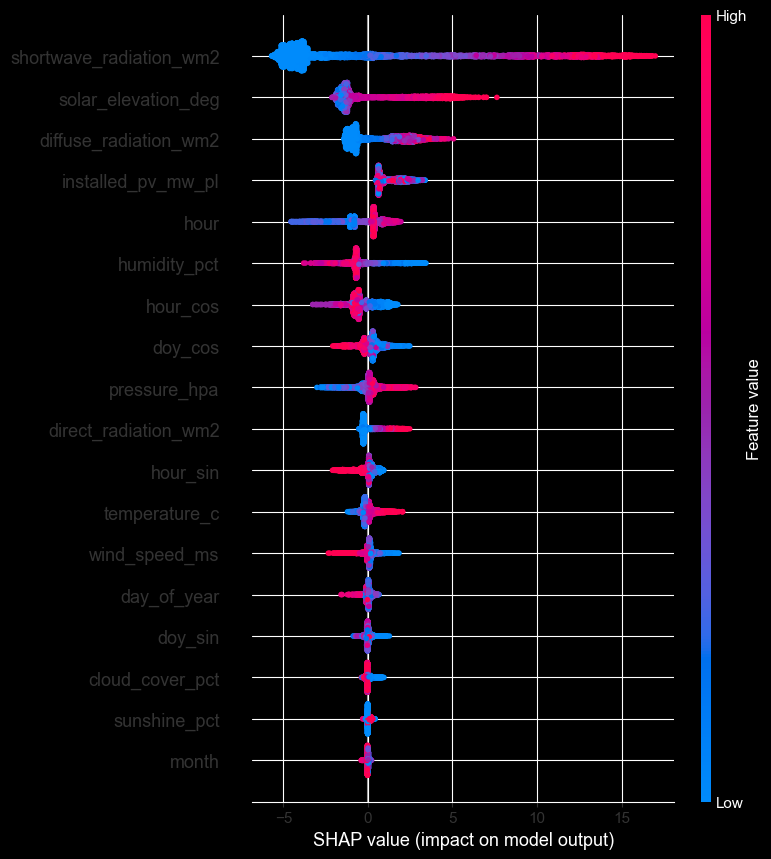

In [15]:
import shap

explainer   = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

In [19]:
import joblib
joblib.dump(final_model, 'artifacts/model_bez_lagow.joblib')
print("Model zapisany.")

Model zapisany.
